# Part 6: Benchmarks

### Ramith Vaid | NTU Singapore

Part 3 included an equal-weight portfolio as a reference and found it ahead of every Max Sharpe portfolio. This part makes the benchmark comparison complete and puts it on a firmer footing. Two benchmarks:

- **Equal weight (1/N)** of the same assets, rebalanced to equal weights at the start of each six-month window (10 bps cost on what is traded), for the 8-stock and the 13-asset universe.
- **S&P 500 buy-and-hold**, using SPY (total return, dividends reinvested), held continuously over the same days with no trading cost.

The strategies are the Part 5 versions: Max Sharpe with the sample covariance, the GARCH covariance with static correlation and the GARCH covariance with DCC correlation (the optimizer's risk-free rate is each window's T-bill yield, Sharpe is measured against the T-bill return actually earned), 35% cap, 10 bps costs, both universes.

**What is measured, beyond return and Sharpe.**
- *Drawdown*: the maximum peak-to-trough fall of the wealth path, the Calmar ratio (return over maximum drawdown) and a Sortino ratio (excess return over downside deviation).
- *Window-by-window*: how often each strategy beat each benchmark over a single six-month window, and the worst and best window.
- *CAPM regression* of daily excess returns on SPY's, with a Newey-West covariance (10 lags): beta, annualized alpha and its t-statistic.
- *Block bootstrap*: 5,000 resamples of the test days in 21-day blocks, the same blocks for every strategy so differences are paired, giving an interval for each Sharpe ratio and the probability that a strategy's Sharpe ratio exceeds a benchmark's.

All strategies are evaluated on the same daily dates (the concatenated test windows, January 2019 to the end of the data). The data end date is pinned to 2026-10-13. Note that both universes are today's large caps and ETFs chosen with hindsight, over a period when US large caps did well, which favors the equal-weight and index benchmarks as much as the optimized portfolios.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    load_or_build_window_inputs, window_risk_free, simulate_strategy_rf, drawdown_path, risk_summary,
    bootstrap_sharpe_differences, capm_regression
)
print('Libraries loaded.')

Libraries loaded.


## 1. Data

In [2]:
tickers8 = ['JPM', 'AAPL', 'XOM', 'JNJ', 'PG', 'CAT', 'NEE', 'AMZN']
tickers13 = tickers8 + ['VNQ', 'TLT', 'EFA', 'EEM', 'GLD']
START, END = '2014-01-01', '2026-10-14'  # END is exclusive: last row is 2026-10-13
prices = pd.DataFrame({t: yf.download(t, start=START, end=END, progress=False)['Close'].squeeze() for t in tickers13 + ['SPY']}).dropna()
log_returns = np.log(prices[tickers13] / prices[tickers13].shift(1)).dropna()
spy = prices['SPY'].pct_change().dropna()
irx = yf.download('^IRX', start=START, end=END, progress=False)['Close'].squeeze().dropna()
tbill_annual = (irx / 100).clip(lower=0.0).reindex(log_returns.index).ffill().bfill()
rf_daily = tbill_annual / 252
inputs8 = load_or_build_window_inputs('cache_window_inputs_8.pkl', log_returns, tickers8)
inputs13 = load_or_build_window_inputs('cache_window_inputs_13.pkl', log_returns, tickers13)
print(f'{len(log_returns)} trading days; {len(inputs8)} windows; first test day {inputs8[0]["test"].index[0].date()}, last {inputs8[-1]["test"].index[-1].date()}')

3213 trading days; 15 windows; first test day 2019-01-07, last 2026-07-15


## 2. Daily return series for every strategy

Cost-blind Max Sharpe with each window's T-bill yield in the optimizer, equal weight rebalanced each window, and SPY over the same dates. Strategy names carry the universe (8 or 13).

In [3]:
COST = 0.0010
series, windows = {}, {}
for uni, inputs, n in (('8', inputs8, 8), ('13', inputs13, 13)):
    rf_win = window_risk_free(inputs, log_returns, tbill_annual)
    for key, label in (('sample', 'Sample'), ('garch_static', 'GARCH static'), ('garch_dcc', 'GARCH DCC'), ('equal_weight', 'Equal weight')):
        wdf, net, gross, W = simulate_strategy_rf(inputs, n, key, COST, rf_win)
        series[f'{label} ({uni})'] = net
        windows[f'{label} ({uni})'] = (1 + net).groupby(np.repeat(np.arange(len(inputs)), [len(w['test']) for w in inputs])).prod() - 1
idx = series['Sample (8)'].index
series['S&P 500 (SPY)'] = spy.reindex(idx)
windows['S&P 500 (SPY)'] = (1 + series['S&P 500 (SPY)']).groupby(np.repeat(np.arange(len(inputs8)), [len(w['test']) for w in inputs8])).prod() - 1
R = pd.DataFrame(series).dropna()
print(f'{len(R)} common days, {R.index[0].date()} to {R.index[-1].date()}; strategies: {list(R.columns)}')

1890 common days, 2019-01-07 to 2026-07-15; strategies: ['Sample (8)', 'GARCH static (8)', 'GARCH DCC (8)', 'Equal weight (8)', 'Sample (13)', 'GARCH static (13)', 'GARCH DCC (13)', 'Equal weight (13)', 'S&P 500 (SPY)']


## 3. Return, risk and drawdown

In [4]:
rows = []
for c in R.columns:
    m = risk_summary(R[c], rf_daily)
    rows.append({'strategy': c, **{k: v for k, v in m.items()}})
summ = pd.DataFrame(rows).set_index('strategy')
summ['ann_return'] *= 100; summ['ann_vol'] *= 100; summ['max_drawdown'] *= 100
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 220)
print(summ.rename(columns={'ann_return': 'return_%', 'ann_vol': 'vol_%', 'max_drawdown': 'max_dd_%'}).to_string())

                   return_%  vol_%  sharpe  max_dd_%  calmar  sortino
strategy                                                             
Sample (8)           19.278 21.142   0.782   -28.141   0.685    1.129
GARCH static (8)     20.026 20.054   0.862   -29.980   0.668    1.234
GARCH DCC (8)        19.517 19.572   0.857   -30.163   0.647    1.231
Equal weight (8)     21.672 17.847   1.061   -30.482   0.711    1.529
Sample (13)          15.718 14.928   0.870   -22.976   0.684    1.257
GARCH static (13)    14.783 14.742   0.817   -23.481   0.630    1.165
GARCH DCC (13)       15.489 14.738   0.865   -22.610   0.685    1.240
Equal weight (13)    16.754 14.578   0.962   -25.879   0.647    1.360
S&P 500 (SPY)        17.459 19.374   0.760   -33.717   0.518    1.071


## 4. Window by window

For each six-month window, the net return of each strategy. Counts of windows in which a strategy beat equal weight (same universe) and SPY, and the worst and best window.

In [5]:
W = pd.DataFrame(windows)
rows = []
for c in W.columns:
    uni = c[c.index('(') :] if c != 'S&P 500 (SPY)' else None
    row = {'strategy': c, 'worst_window_%': W[c].min() * 100, 'best_window_%': W[c].max() * 100, 'positive_windows': int((W[c] > 0).sum()),
           'beats_SPY': int((W[c] > W['S&P 500 (SPY)']).sum()) if c != 'S&P 500 (SPY)' else None}
    if uni:
        eq = f'Equal weight {uni}'
        row['beats_equal_weight'] = int((W[c] > W[eq]).sum()) if c != eq else None
    rows.append(row)
wtab = pd.DataFrame(rows).set_index('strategy')
print(f'{len(W)} windows')
print(wtab.to_string())

15 windows
                   worst_window_%  best_window_%  positive_windows  beats_SPY  beats_equal_weight
strategy                                                                                         
Sample (8)                -17.386         22.268                12      7.000               8.000
GARCH static (8)          -16.043         22.316                13     10.000               7.000
GARCH DCC (8)             -16.277         22.288                13     11.000               7.000
Equal weight (8)           -9.604         23.442                14      8.000                 NaN
Sample (13)               -16.522         26.287                13      7.000               6.000
GARCH static (13)         -16.246         25.736                13      6.000               6.000
GARCH DCC (13)            -16.125         25.709                13      8.000               6.000
Equal weight (13)         -12.107         18.927                14      7.000                 NaN
S&P 500 (

## 5. CAPM regression on SPY

Daily excess returns of each strategy on SPY's. Alpha is annualized; a t-statistic above about 2 would indicate a return in excess of what market exposure explains.

In [6]:
rows = []
for c in R.columns:
    if c == 'S&P 500 (SPY)':
        continue
    reg = capm_regression(R[c], R['S&P 500 (SPY)'], rf_daily)
    rows.append({'strategy': c, 'beta': reg['beta'], 'alpha_ann_%': reg['alpha_ann'] * 100, 't_alpha': reg['t_alpha'], 'R2': reg['r2']})
capm = pd.DataFrame(rows).set_index('strategy')
print(capm.to_string())

                   beta  alpha_ann_%  t_alpha    R2
strategy                                           
Sample (8)        0.922        3.088    0.739 0.713
GARCH static (8)  0.881        4.111    1.088 0.725
GARCH DCC (8)     0.862        3.877    1.071 0.729
Equal weight (8)  0.826        5.894    2.239 0.804
Sample (13)       0.573        4.268    1.272 0.552
GARCH static (13) 0.579        3.332    0.998 0.579
GARCH DCC (13)    0.595        3.697    1.154 0.612
Equal weight (13) 0.686        3.373    1.567 0.832


## 6. Block bootstrap of the Sharpe ratio

5,000 resamples of the 1,890 or so test days in 21-day blocks. For each strategy, the median and 90% interval of the Sharpe ratio, and for each Max Sharpe strategy the probability that its Sharpe ratio exceeds equal weight (same universe) and SPY.

In [7]:
boot = bootstrap_sharpe_differences(R, rf_daily, n_boot=5000, block=21, seed=0)
rows = []
for c in R.columns:
    s = boot[c]
    row = {'strategy': c, 'sharpe_point': summ.loc[c, 'sharpe'], 'boot_median': np.median(s), 'boot_5%': np.percentile(s, 5), 'boot_95%': np.percentile(s, 95)}
    if c != 'S&P 500 (SPY)':
        uni = c[c.index('('):]
        eq = f'Equal weight {uni}'
        if c != eq:
            row['P(Sharpe > equal weight)'] = float(np.mean(s > boot[eq]))
        row['P(Sharpe > SPY)'] = float(np.mean(s > boot['S&P 500 (SPY)']))
    rows.append(row)
bs = pd.DataFrame(rows).set_index('strategy')
print(bs.to_string())
print()
d = boot['Equal weight (8)'] - boot['S&P 500 (SPY)']
print(f'Equal weight (8) minus SPY, Sharpe: median {np.median(d):+.3f}, 90% interval {np.percentile(d, 5):+.3f} to {np.percentile(d, 95):+.3f}')
d = boot['Equal weight (13)'] - boot['S&P 500 (SPY)']
print(f'Equal weight (13) minus SPY, Sharpe: median {np.median(d):+.3f}, 90% interval {np.percentile(d, 5):+.3f} to {np.percentile(d, 95):+.3f}')

                   sharpe_point  boot_median  boot_5%  boot_95%  P(Sharpe > equal weight)  P(Sharpe > SPY)
strategy                                                                                                  
Sample (8)                0.782        0.791    0.140     1.588                     0.113            0.520
GARCH static (8)          0.862        0.888    0.222     1.692                     0.164            0.662
GARCH DCC (8)             0.857        0.880    0.217     1.684                     0.149            0.656
Equal weight (8)          1.061        1.093    0.383     1.922                       NaN            0.959
Sample (13)               0.870        0.879    0.260     1.589                     0.336            0.620
GARCH static (13)         0.817        0.825    0.194     1.567                     0.267            0.568
GARCH DCC (13)            0.865        0.875    0.241     1.626                     0.329            0.640
Equal weight (13)         0.962      

## 7. Chart

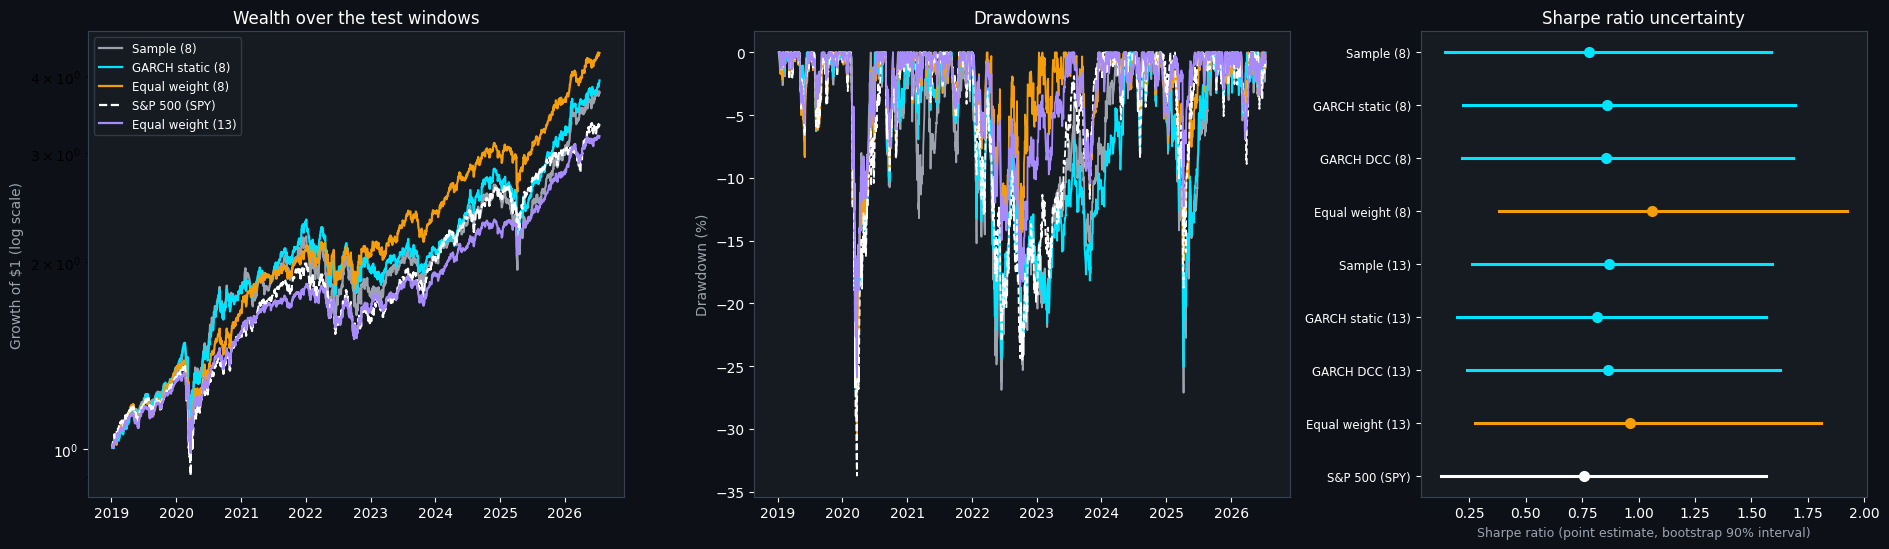

Saved chart_part6_benchmarks.png


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw={'width_ratios': [1.2, 1.2, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')
show = [('Sample (8)', '#9ca3af', '-'), ('GARCH static (8)', '#00e5ff', '-'), ('Equal weight (8)', '#f59e0b', '-'), ('S&P 500 (SPY)', '#ffffff', '--'), ('Equal weight (13)', '#a78bfa', '-')]
ax = axes[0]
for c, col, ls in show:
    ax.plot(R.index, (1 + R[c]).cumprod(), color=col, lw=1.6, ls=ls, label=c)
ax.set_yscale('log')
ax.set_ylabel('Growth of $1 (log scale)', color='#9ca3af')
ax.set_title('Wealth over the test windows', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8.5, loc='upper left')
ax = axes[1]
for c, col, ls in show:
    ax.plot(R.index, drawdown_path(R[c]) * 100, color=col, lw=1.3, ls=ls)
ax.set_ylabel('Drawdown (%)', color='#9ca3af')
ax.set_title('Drawdowns', color='white', fontsize=12)
ax = axes[2]
order = list(R.columns)
y = np.arange(len(order))[::-1]
for yi, c in zip(y, order):
    lo, hi, med = bs.loc[c, 'boot_5%'], bs.loc[c, 'boot_95%'], bs.loc[c, 'sharpe_point']
    col = '#ffffff' if c.startswith('S&P') else ('#f59e0b' if c.startswith('Equal') else '#00e5ff')
    ax.plot([lo, hi], [yi, yi], color=col, lw=2.2)
    ax.plot(med, yi, 'o', color=col, ms=7)
ax.set_yticks(y)
ax.set_yticklabels(order, color='white', fontsize=8.5)
ax.set_xlabel('Sharpe ratio (point estimate, bootstrap 90% interval)', color='#9ca3af', fontsize=9)
ax.set_title('Sharpe ratio uncertainty', color='white', fontsize=12)
plt.tight_layout()
plt.savefig('chart_part6_benchmarks.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part6_benchmarks.png')

## 8. Summary and saved tables

In [9]:
summ.rename(columns={'ann_return': 'return_pct', 'ann_vol': 'vol_pct', 'max_drawdown': 'max_dd_pct'}).to_csv('part6_benchmark_summary.csv')
wtab.to_csv('part6_window_comparison.csv')
W.to_csv('part6_window_returns.csv')
capm.to_csv('part6_capm.csv')
bs.to_csv('part6_bootstrap_sharpe.csv')
print('=' * 70)
print('PART 6 SUMMARY: BENCHMARKS')
print('=' * 70)
print(summ.rename(columns={'ann_return': 'return_%', 'ann_vol': 'vol_%', 'max_drawdown': 'max_dd_%'}).round(3).to_string())
print()
print('Files saved: chart_part6_benchmarks.png, part6_benchmark_summary.csv, part6_window_comparison.csv, part6_window_returns.csv, part6_capm.csv, part6_bootstrap_sharpe.csv')

PART 6 SUMMARY: BENCHMARKS
                   return_%  vol_%  sharpe  max_dd_%  calmar  sortino
strategy                                                             
Sample (8)           19.278 21.142   0.782   -28.141   0.685    1.129
GARCH static (8)     20.026 20.054   0.862   -29.980   0.668    1.234
GARCH DCC (8)        19.517 19.572   0.857   -30.163   0.647    1.231
Equal weight (8)     21.672 17.847   1.061   -30.482   0.711    1.529
Sample (13)          15.718 14.928   0.870   -22.976   0.684    1.257
GARCH static (13)    14.783 14.742   0.817   -23.481   0.630    1.165
GARCH DCC (13)       15.489 14.738   0.865   -22.610   0.685    1.240
Equal weight (13)    16.754 14.578   0.962   -25.879   0.647    1.360
S&P 500 (SPY)        17.459 19.374   0.760   -33.717   0.518    1.071

Files saved: chart_part6_benchmarks.png, part6_benchmark_summary.csv, part6_window_comparison.csv, part6_window_returns.csv, part6_capm.csv, part6_bootstrap_sharpe.csv
